# Análisis Geoespacial IPM - Zona de Intervención: Ciudad Paraíso

Este notebook prioriza la visualización cartográfica de las 5 variables más relevantes del Índice de Pobreza Multidimensional (IPM) en la zona de intervención **Ciudad Paraíso**.

### Contexto y Cifras Generales (Corte Mayo 2026)

Para la interpretación de los resultados, se deben considerar dos lógicas opuestas:
1. **Índice de Condición Social (ICS):** Es un indicador directo; un valor del **100% representa el escenario óptimo** (bienestar y acceso pleno).
2. **Índice de Pobreza Multidimensional (IPM):** Es un indicador inverso; un valor del **100% representa el escenario crítico** (pobreza absoluta).

A nivel distrital, Cali presenta una marcada brecha territorial. La **severidad de la pobreza (IPM promedio en manzanas con incidencia > 0)** es del **15.28% en el área urbana**, mientras que en el **área rural se dispara al 38.33%**, impulsada principalmente por carencias en infraestructura básica en los corregimientos.

Este análisis se enfoca en la zona de Ciudad Paraíso para identificar las privaciones específicas que afectan a este territorio de intervención. Todas las fuentes utilizadas están en formato **GeoJSON** (IPM, ICS, manzanas catastrales y polígono del área de estudio).

In [1]:
# 1. Instalación de dependencias (solo en Colab)
import sys
if 'google.colab' in sys.modules:
    !pip install geopandas matplotlib seaborn openpyxl -q

In [2]:
# 2. Importar librerías
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np
import matplotlib.colors as mcolors
from matplotlib.patheffects import withStroke
import matplotlib.patches as mpatches

sns.set_style('white')
print('Librerías listas')

Librerías listas


In [3]:
# 3. Definir rutas con detección de entorno
REPO_URL = 'https://github.com/j0rg3c45/Pobreza_multidimensional_y_condicion_social.git'
REPO_DIR = 'Pobreza_multidimensional_y_condicion_social'

if 'google.colab' in sys.modules:
    if not os.path.exists(REPO_DIR):
        !git clone {REPO_URL}
    else:
        !cd {REPO_DIR} && git pull
    BASE_DIR = REPO_DIR
else:
    if os.path.exists('indice_Pobreza'): BASE_DIR = '.'
    elif os.path.exists('../indice_Pobreza'): BASE_DIR = '..'
    elif os.path.exists('../../indice_Pobreza'): BASE_DIR = '../..'
    else: BASE_DIR = '.'

DATA_BASE = os.path.join(BASE_DIR, 'indice_Pobreza/data')

# Capas (todas en formato GeoJSON)
PATH_IPM_VARS_FULL  = os.path.join(DATA_BASE, 'geojson_ipm/Mzn_ipm_variables.geojson')
PATH_ICS_FULL       = os.path.join(DATA_BASE, 'geojosn_ICS/ics_mzn.geojson')
PATH_MANZANAS_FONDO = os.path.join(DATA_BASE, 'geojson_Manzanas_catastrales/geojson_Manzanas_catastrales.geojson')
PATH_AREA_ESTUDIO   = os.path.join(DATA_BASE, 'geojson_poligonos_territorio_ITT/poligono_ciudad_Paraiso.geojson')

# Cargar datos
gdf_full  = gpd.read_file(PATH_IPM_VARS_FULL)
gdf_ics_full = gpd.read_file(PATH_ICS_FULL)
gdf_fondo = gpd.read_file(PATH_MANZANAS_FONDO)
gdf_area  = gpd.read_file(PATH_AREA_ESTUDIO)

# Unificar CRS a WGS84 (el polígono de Paraíso viene en ESRI:103599)
gdf_full     = gdf_full.to_crs('EPSG:4326')
gdf_ics_full = gdf_ics_full.to_crs('EPSG:4326')
gdf_fondo    = gdf_fondo.to_crs('EPSG:4326')
gdf_area     = gdf_area.to_crs('EPSG:4326')

# --- Filtrado espacial preciso: centroide de la manzana DENTRO del polígono ---
# Se reproyecta a EPSG:3115 (metros) para precisión métrica del centroide.
area_p = gdf_area.to_crs('EPSG:3115')

# IPM
ipm_p = gdf_full.to_crs('EPSG:3115')
idx_ipm = gpd.sjoin(ipm_p.copy().assign(geometry=ipm_p.centroid),
                    area_p[['geometry']], how='inner', predicate='within').index
gdf = gdf_full.loc[idx_ipm].copy()

# ICS
ics_p = gdf_ics_full.to_crs('EPSG:3115')
idx_ics = gpd.sjoin(ics_p.copy().assign(geometry=ics_p.centroid),
                    area_p[['geometry']], how='inner', predicate='within').index
gdf_ics = gdf_ics_full.loc[idx_ics].copy()

print(f'Manzanas IPM detectadas en Ciudad Paraíso: {len(gdf)}')
print(f'Manzanas ICS detectadas en Ciudad Paraíso: {len(gdf_ics)}')

Manzanas IPM detectadas en Ciudad Paraíso: 33
Manzanas ICS detectadas en Ciudad Paraíso: 33


In [4]:
# 4. Consolidar IPM + ICS por manzana (COD_MZN, 22 caracteres, común a ambas capas GeoJSON)
# Nota: en estos GeoJSON el COD_MZN ya está homologado a 22 chars en ambas capas,
# por lo que el cruce es directo (no requiere la transformación 24->22 del Excel).
ics_cols = gdf_ics[['COD_MZN', 'ics']].copy()
gdf = gdf.merge(ics_cols, on='COD_MZN', how='left')

n_con_ics = gdf['ics'].notna().sum()
print(f'Manzanas IPM con valor ICS cruzado: {n_con_ics} de {len(gdf)}')
print(f"IPM global promedio (Ciudad Paraíso): {gdf['ipm'].mean():.2f}")
print(f"ICS promedio (Ciudad Paraíso):        {gdf['ics'].mean():.2f}")
gdf[['COD_MZN', 'ipm', 'ics']].head()

Manzanas IPM con valor ICS cruzado: 31 de 33
IPM global promedio (Ciudad Paraíso): 26.52
ICS promedio (Ciudad Paraíso):        23.07


,COD_MZN,ipm,ics
0,7600110000000003090209,29.5,25.883636
1,7600110000000003090210,6.8,30.590372
2,7600110000000003090211,12.5,29.587500
3,7600110000000003090212,21.9,25.406250
4,7600110000000003090213,34.4,22.968000


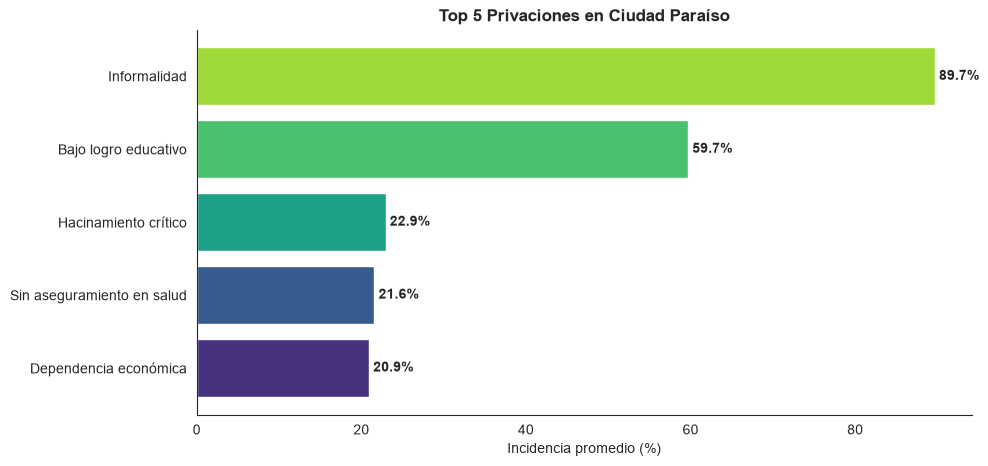

In [5]:
# 5. Escalas Maestras Notebook 01 (Comparabilidad Distrital)
RANGOS_IPM_8 = [
    (0.4, 20.0, "0.4% - 20.0%"),
    (20.1, 27.0, "20.1% - 27.0%"),
    (27.1, 33.1, "27.1% - 33.1%"),
    (33.2, 39.8, "33.2% - 39.8%"),
    (39.9, 48.6, "39.9% - 48.6%"),
    (48.7, 60.6, "48.7% - 60.6%"),
    (60.7, 80.0, "60.7% - 80.0%"),
    (80.1, 100.0, "80.1% - 100.0%"),
]
# Usamos Viridis para variables IPM segun mandato de accesibilidad
cmap_master = plt.get_cmap("viridis", 8)
COLORES_IPM_8 = [mcolors.to_hex(cmap_master(i)) for i in range(8)]
CATEGORIAS_IPM_8 = ["Bajo", "Moderado-Bajo", "Moderado", "Moderado-Alto", "Alto", "Muy Alto", "Extremo", "Extremo Maximo"]

def _clasificar_ipm_master(gdf_zone, columna):
    datos = gdf_zone[columna].astype(float)
    cortes = [r[0] for r in RANGOS_IPM_8] + [RANGOS_IPM_8[-1][1]]
    etiquetas = [r[2] for r in RANGOS_IPM_8]
    res = gdf_zone.copy()
    res["_rango"] = pd.cut(datos, bins=cortes, labels=etiquetas, include_lowest=True, duplicates="drop")
    col_map = dict(zip(etiquetas, COLORES_IPM_8))
    res["_color"] = res["_rango"].astype(str).map(col_map).fillna("#BDBDBD")
    return res

COLS_MAP = {
    'ANALF_': 'Analfabetismo', 'BAJO_': 'Bajo logro educativo',
    'INFANCIA_': 'Barreras primera infancia', 'INASIS_': 'Inasistencia escolar',
    'REZAGO_': 'Rezago escolar', 'TRAB_INFAN': 'Trabajo infantil',
    'DEPEN_': 'Dependencia económica', 'INFOR_': 'Informalidad',
    'SALUD_': 'Barreras de salud', 'ASEGU_': 'Sin aseguramiento en salud',
    'HACI_': 'Hacinamiento crítico', 'PARED_': 'Paredes precarias',
    'EXCRE_': 'Eliminación inadecuada de excretas', 'PISOS_': 'Pisos precarios',
    'AGUA_': 'Sin acceso a agua mejorada'
}
top_5 = gdf[list(COLS_MAP.keys())].mean().sort_values(ascending=False).head(5).index.tolist()

# Visualizacion Ranking Top 5
top_means = gdf[top_5].mean().sort_values(ascending=True)
plt.figure(figsize=(10, 5))
plt.barh([COLS_MAP[c] for c in top_means.index], top_means.values, color=cmap_master(np.linspace(0.2, 0.8, 5)))
for i, v in enumerate(top_means.values): plt.text(v + 0.5, i, f"{v:.1f}%", va='center', fontweight='bold')
plt.title("Top 5 Privaciones en Ciudad Paraíso", fontweight='bold')
plt.xlabel("Incidencia promedio (%)")
sns.despine()
plt.show()

In [6]:
# 6. Motor de Mapeo Maestro (Sincronización Total Colab 1)
def plot_ipm_variable_master(gdf_zone, gdf_back, gdf_poly, column, title):
    fig, ax = plt.subplots(1, 1, figsize=(18, 12))
    # --- 1. Capa Base (Cubre todo el lienzo) ---
    gdf_back.plot(ax=ax, color="#F8F8F8", edgecolor="#DCDCDC", linewidth=0.1, alpha=0.8, zorder=1)
    # --- 2. Clasificación Maestra ---
    gdf_cl = _clasificar_ipm_master(gdf_zone, column)
    # --- 3. Ploteo de Manzanas y Borde ---
    gdf_cl.plot(ax=ax, color=gdf_cl["_color"], edgecolor="white", linewidth=0.35, zorder=3, alpha=0.9)
    gdf_poly.boundary.plot(ax=ax, color="#D55E00", linewidth=1.5, linestyle="-", alpha=0.8, zorder=2)
    # --- 4. Etiquetas de Datos (Contraste Maestro) ---
    for _, fila in gdf_cl.iterrows():
        if pd.isna(fila[column]): continue
        punto = fila.geometry.representative_point()
        valor = float(fila[column])
        txt_color = "white" if valor > 0 else "black"
        stk_color = "black" if valor > 0 else "white"
        ax.text(punto.x, punto.y, f"{valor:.1f}", fontsize=7, ha="center", va="center", fontweight="bold",
                color=txt_color, path_effects=[withStroke(linewidth=1.5, foreground=stk_color, alpha=0.8)], zorder=5)
    # --- 5. Ajuste de Vista 'Efecto Atlas' ---
    minx, miny, maxx, maxy = gdf_cl.total_bounds
    rx, ry = maxx - minx, maxy - miny
    ax.set_xlim(minx - rx*0.15, maxx + rx*0.75) # Expansión 75% derecha
    ax.set_ylim(miny - ry*0.15, maxy + ry*0.15)
    # --- 6. Leyenda Maestra ---
    handles = [mpatches.Patch(facecolor=COLORES_IPM_8[i], edgecolor="white", label=f"{RANGOS_IPM_8[i][2]} | {CATEGORIAS_IPM_8[i]}") for i in range(8)]
    handles.append(mpatches.Patch(facecolor="none", edgecolor="#D55E00", linewidth=1.5, label="Area de estudio"))
    ax.legend(handles=handles, title=f"Privación: {title.upper()}\nRango % | Categoría",
              loc="center right", frameon=True, framealpha=0.9, fontsize=9, title_fontsize=11)
    ax.set_title(f"IPM por manzana: {title.upper()} - Ciudad Paraíso", fontsize=16, fontweight="bold", pad=20)
    ax.set_axis_off()
    plt.subplots_adjust(left=0.01, right=0.99, top=0.92, bottom=0.01)
    plt.show()

Generando mapas sincronizados con el Estándar Maestro del Notebook 01...


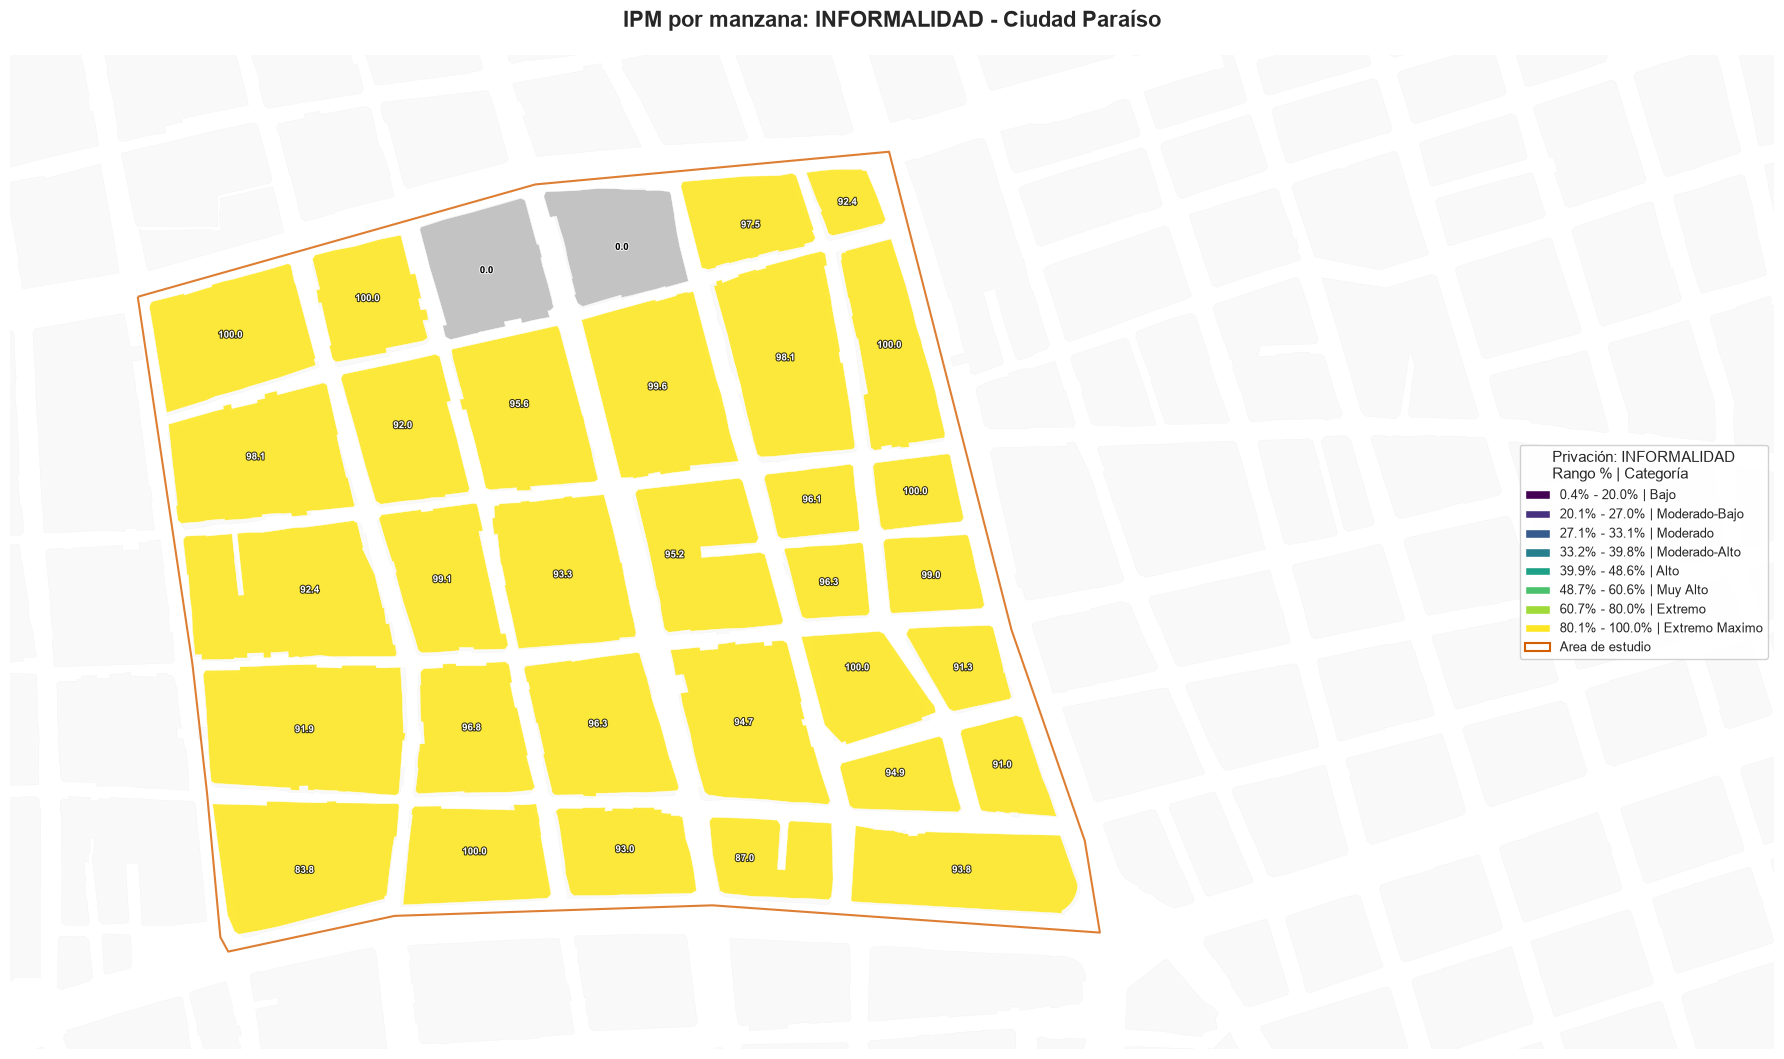

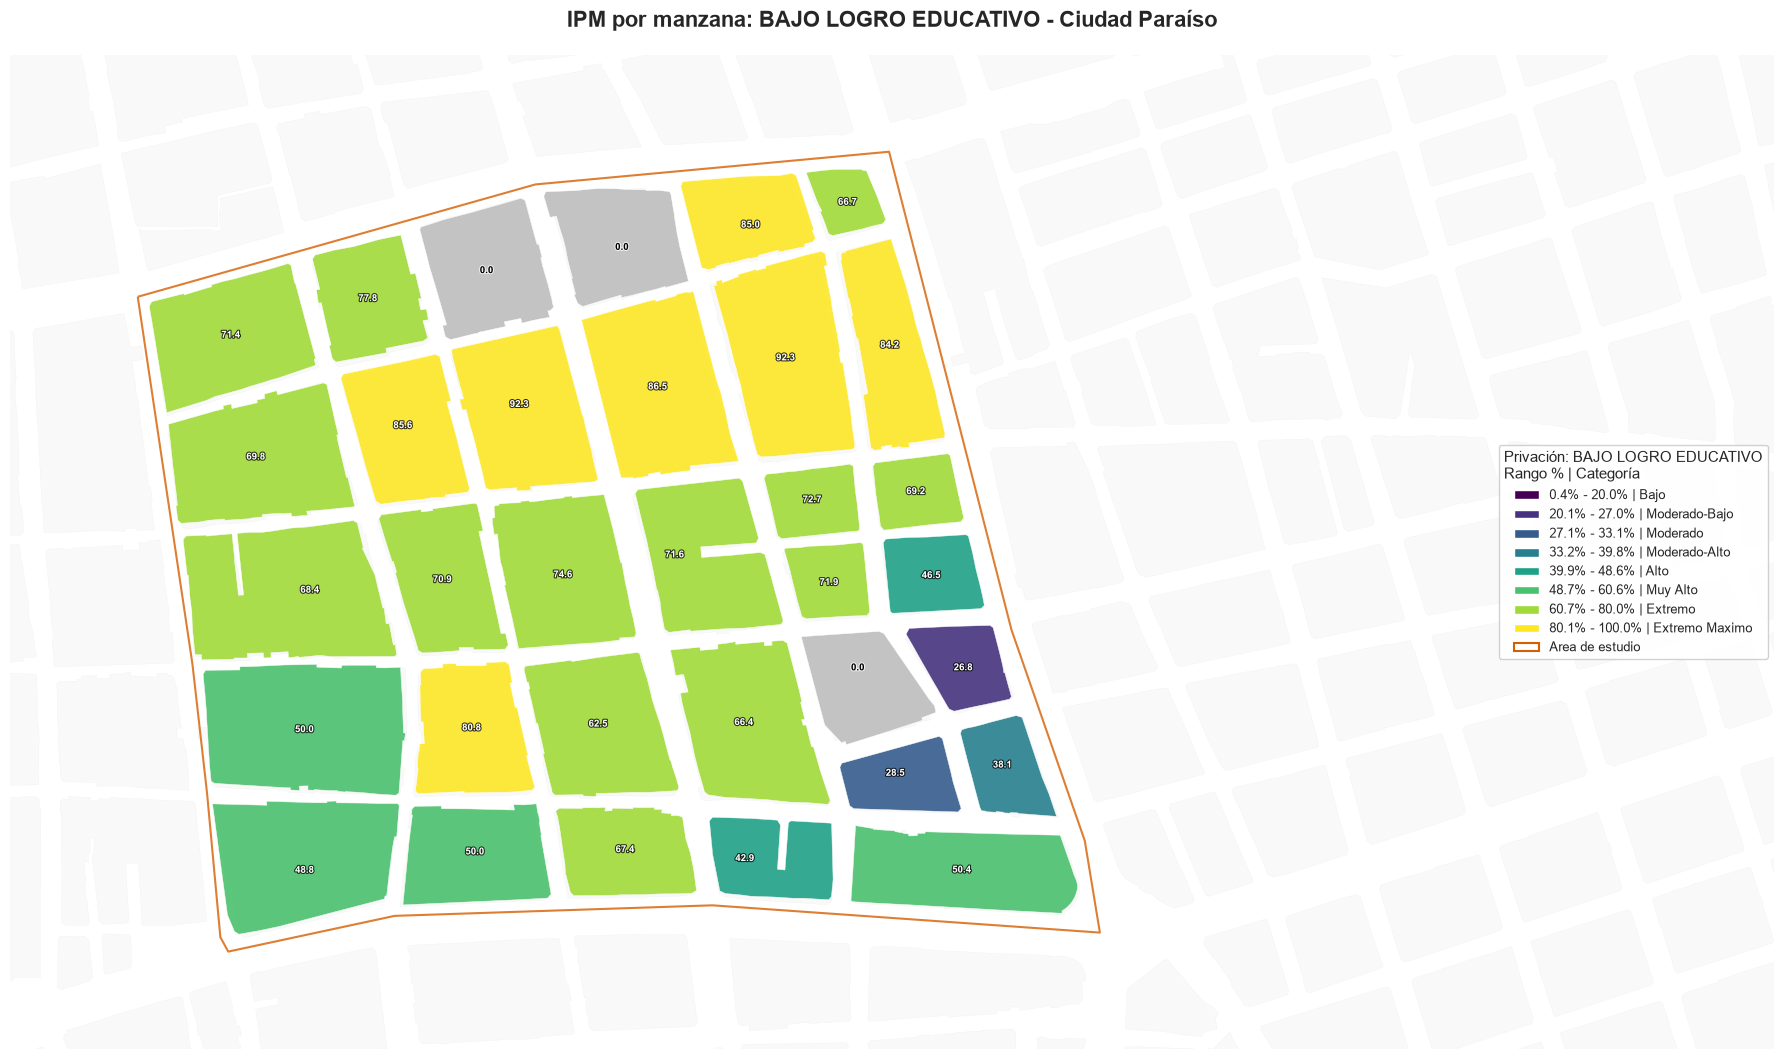

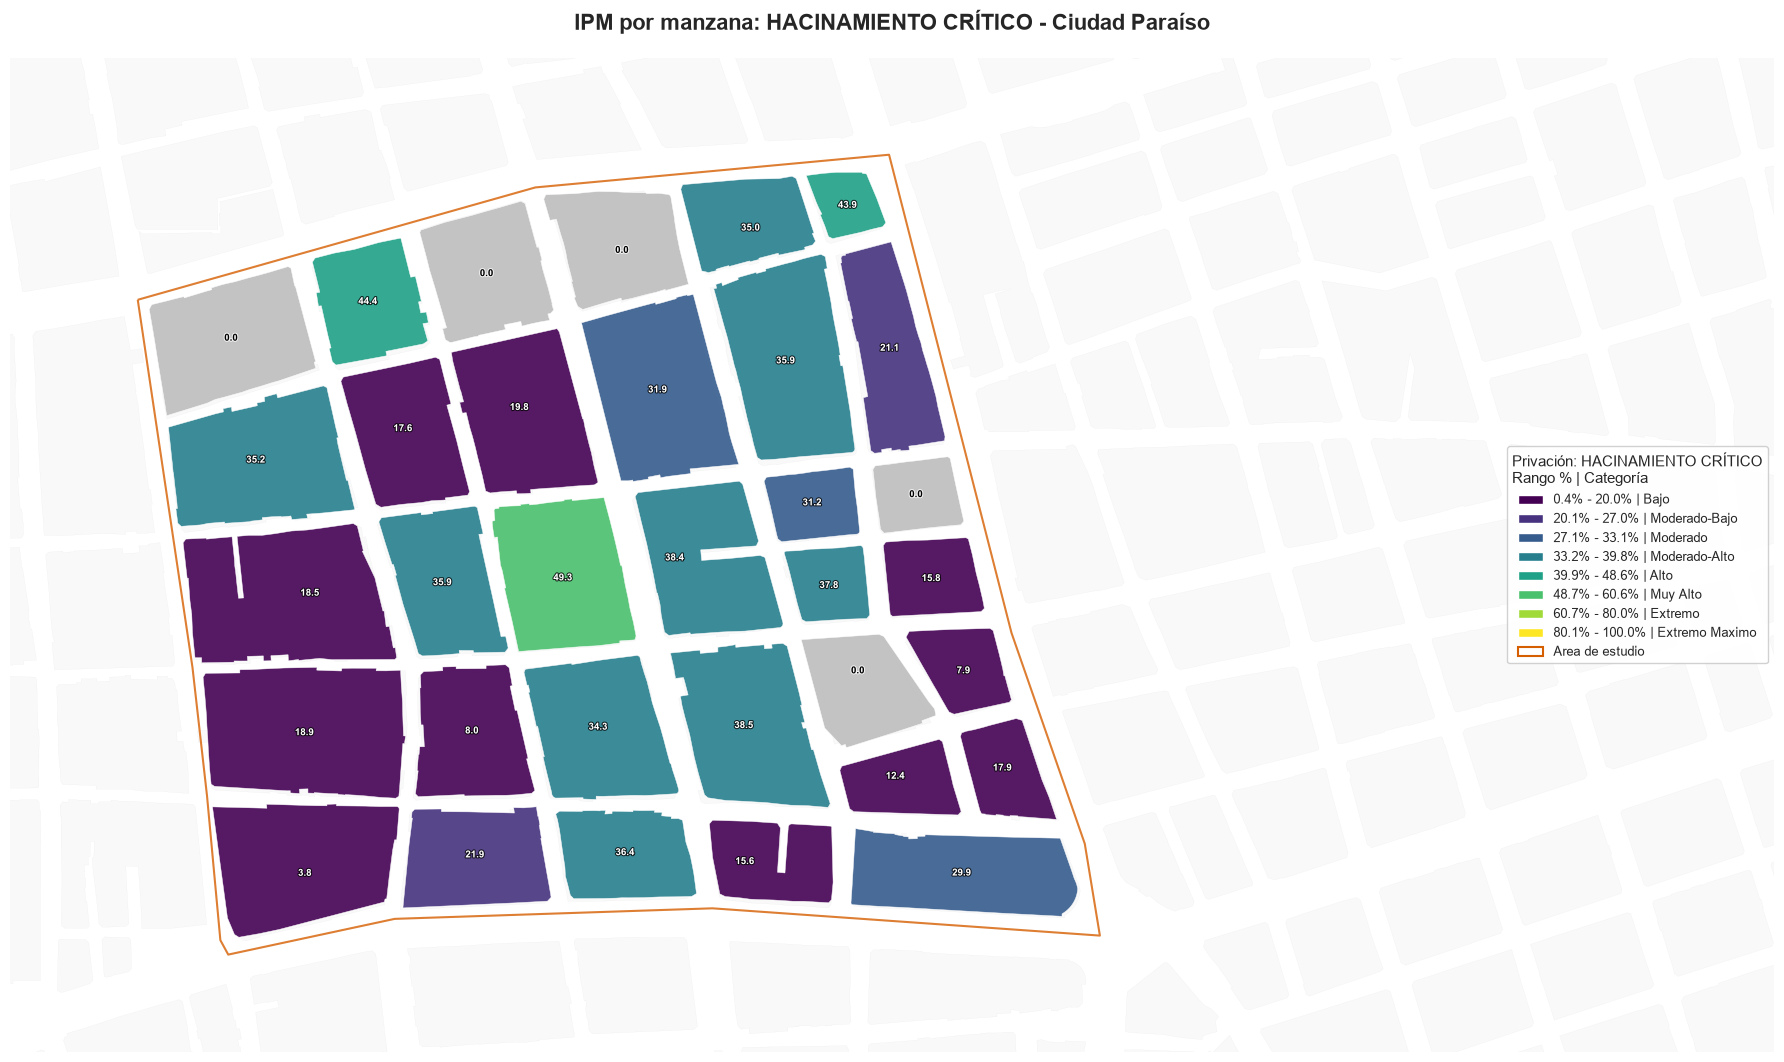

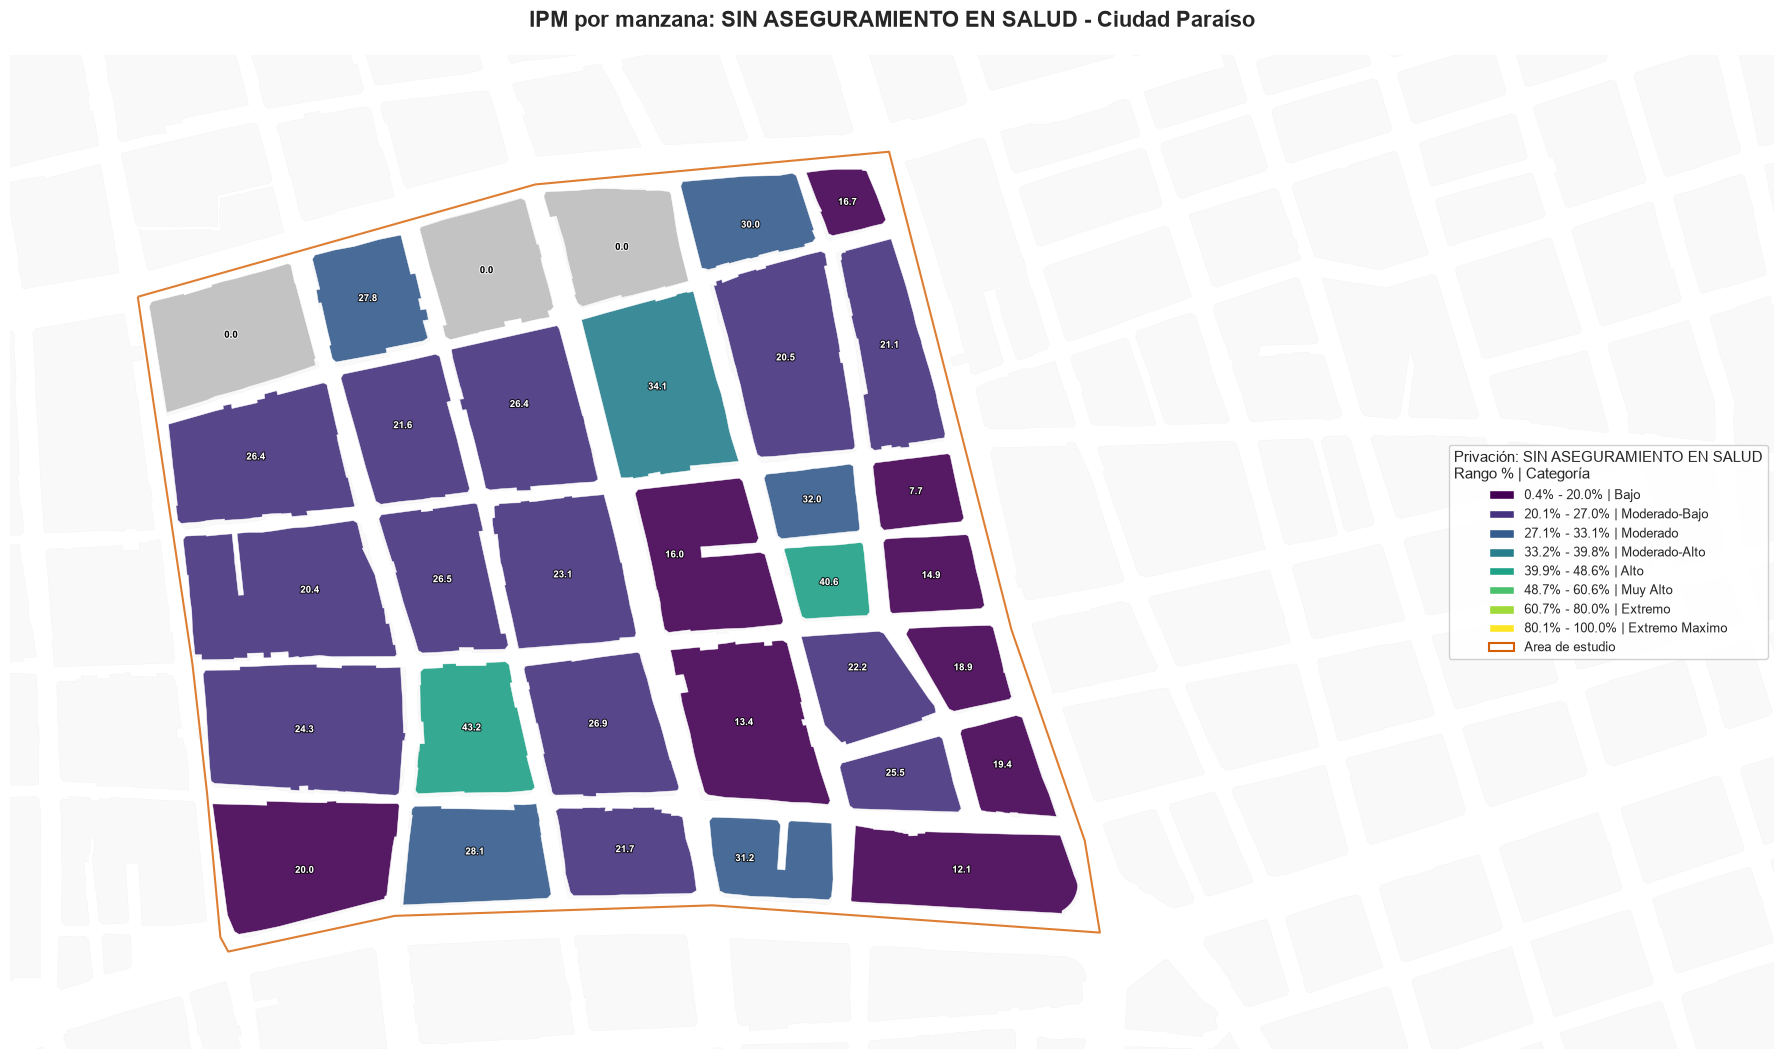

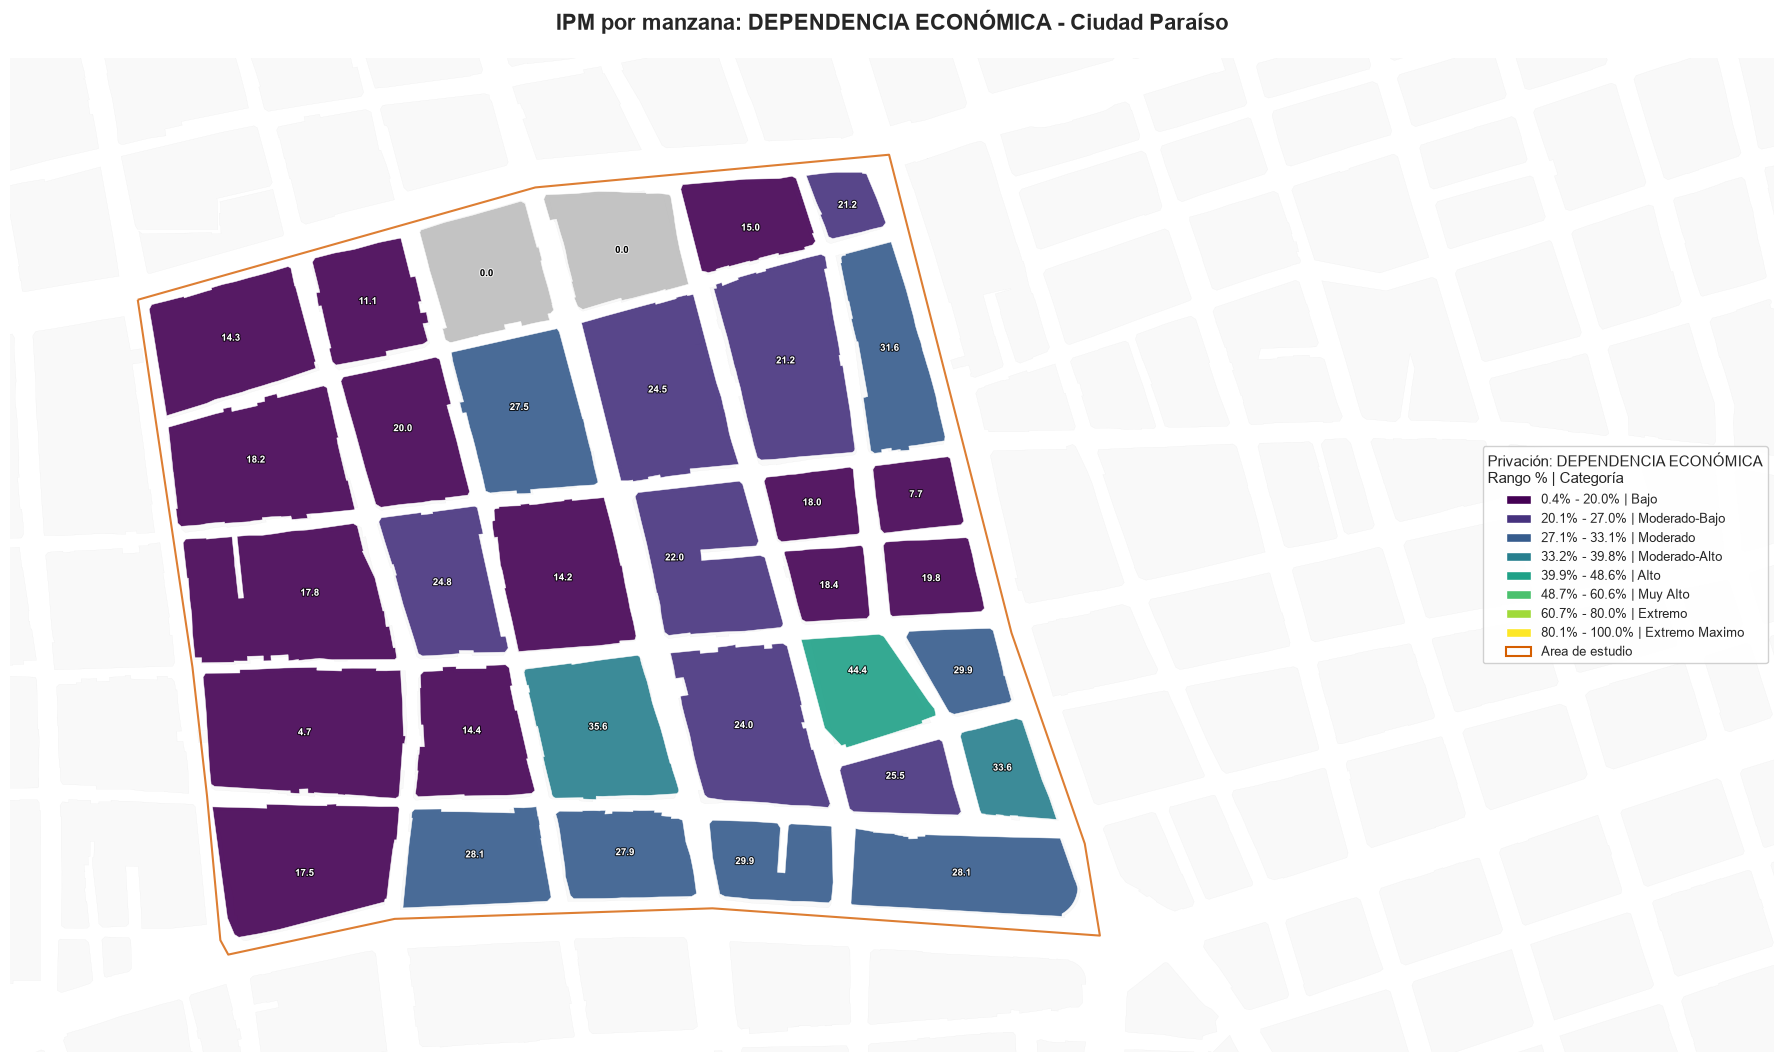

In [7]:
# 7. Ejecución de la Cartografía Maestra (Top 5 variables IPM)
print("Generando mapas sincronizados con el Estándar Maestro del Notebook 01...")
for var in top_5:
    plot_ipm_variable_master(gdf, gdf_fondo, gdf_area, var, COLS_MAP[var])

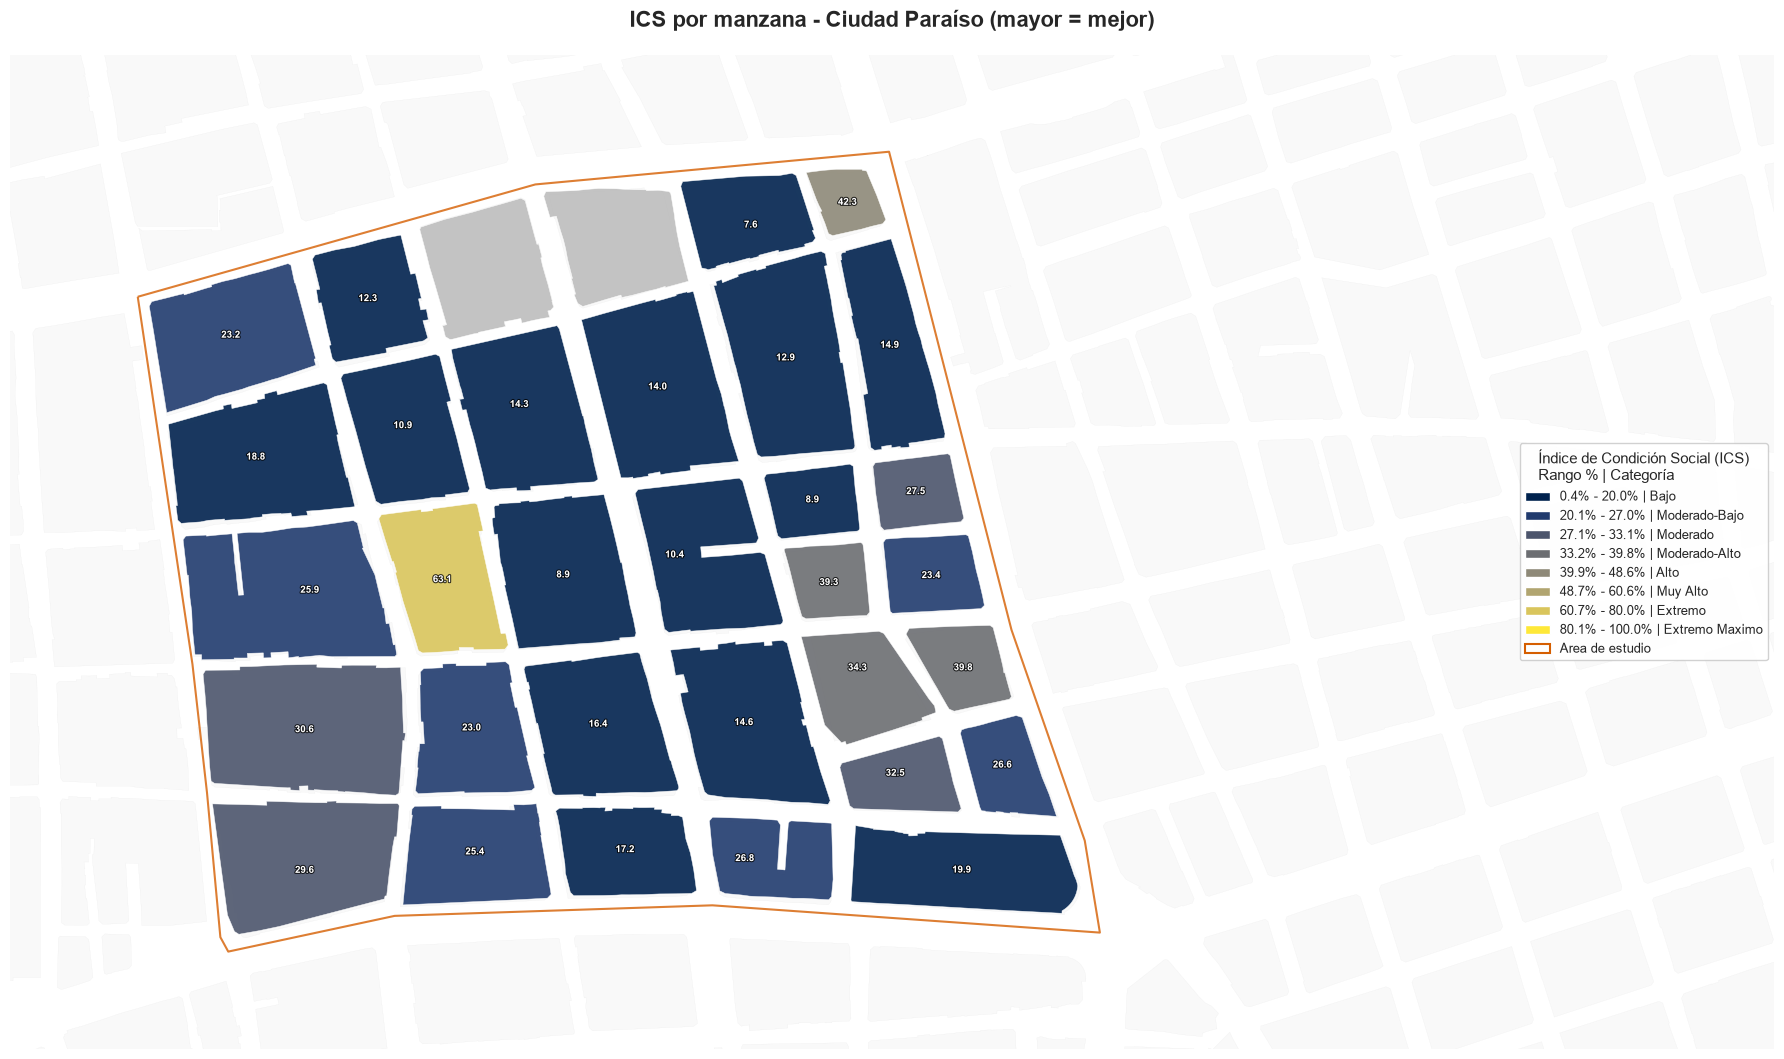

In [8]:
# 8. Mapa del Índice de Condición Social (ICS) en Ciudad Paraíso
# ICS es un indicador DIRECTO (mayor = mejor). Se usa la paleta cividis segun estándar del proyecto.
RANGOS_ICS_8 = RANGOS_IPM_8  # mismos cortes numéricos; cambia la paleta e interpretación
cmap_ics = plt.get_cmap("cividis", 8)
COLORES_ICS_8 = [mcolors.to_hex(cmap_ics(i)) for i in range(8)]

def plot_ics_master(gdf_zone, gdf_back, gdf_poly):
    datos = gdf_zone['ics'].astype(float)
    cortes = [r[0] for r in RANGOS_ICS_8] + [RANGOS_ICS_8[-1][1]]
    etiquetas = [r[2] for r in RANGOS_ICS_8]
    gz = gdf_zone.copy()
    gz['_rango'] = pd.cut(datos, bins=cortes, labels=etiquetas, include_lowest=True, duplicates='drop')
    col_map = dict(zip(etiquetas, COLORES_ICS_8))
    gz['_color'] = gz['_rango'].astype(str).map(col_map).fillna('#BDBDBD')

    fig, ax = plt.subplots(1, 1, figsize=(18, 12))
    gdf_back.plot(ax=ax, color="#F8F8F8", edgecolor="#DCDCDC", linewidth=0.1, alpha=0.8, zorder=1)
    gz.plot(ax=ax, color=gz['_color'], edgecolor='white', linewidth=0.35, zorder=3, alpha=0.9)
    gdf_poly.boundary.plot(ax=ax, color="#D55E00", linewidth=1.5, linestyle='-', alpha=0.8, zorder=2)
    for _, fila in gz.iterrows():
        if pd.isna(fila['ics']): continue
        punto = fila.geometry.representative_point()
        valor = float(fila['ics'])
        ax.text(punto.x, punto.y, f"{valor:.1f}", fontsize=7, ha='center', va='center', fontweight='bold',
                color='white', path_effects=[withStroke(linewidth=1.5, foreground='black', alpha=0.8)], zorder=5)
    minx, miny, maxx, maxy = gz.total_bounds
    rx, ry = maxx - minx, maxy - miny
    ax.set_xlim(minx - rx*0.15, maxx + rx*0.75)
    ax.set_ylim(miny - ry*0.15, maxy + ry*0.15)
    handles = [mpatches.Patch(facecolor=COLORES_ICS_8[i], edgecolor='white', label=f"{RANGOS_ICS_8[i][2]} | {CATEGORIAS_IPM_8[i]}") for i in range(8)]
    handles.append(mpatches.Patch(facecolor='none', edgecolor='#D55E00', linewidth=1.5, label='Area de estudio'))
    ax.legend(handles=handles, title="Índice de Condición Social (ICS)\nRango % | Categoría",
              loc='center right', frameon=True, framealpha=0.9, fontsize=9, title_fontsize=11)
    ax.set_title("ICS por manzana - Ciudad Paraíso (mayor = mejor)", fontsize=16, fontweight='bold', pad=20)
    ax.set_axis_off()
    plt.subplots_adjust(left=0.01, right=0.99, top=0.92, bottom=0.01)
    plt.show()

if gdf['ics'].notna().any():
    plot_ics_master(gdf, gdf_fondo, gdf_area)
else:
    print('No hay valores ICS disponibles para las manzanas de la zona.')

In [9]:
# 9. Exportar capas filtradas de Ciudad Paraíso en formato GeoJSON
OUT_DIR = os.path.join(BASE_DIR, 'indice_Pobreza/outputs/ciudad_paraiso')
os.makedirs(OUT_DIR, exist_ok=True)

# IPM (15 variables + ipm global + ics cruzado) para las manzanas de la zona
out_ipm = os.path.join(OUT_DIR, 'IPM_ciudad_paraiso.geojson')
gdf.to_crs('EPSG:4326').to_file(out_ipm, driver='GeoJSON')

# ICS para las manzanas de la zona
out_ics = os.path.join(OUT_DIR, 'ICS_ciudad_paraiso.geojson')
gdf_ics.to_crs('EPSG:4326').to_file(out_ics, driver='GeoJSON')

print('Exportado:')
print(' -', out_ipm, f'({len(gdf)} manzanas)')
print(' -', out_ics, f'({len(gdf_ics)} manzanas)')

Exportado:
 - ../..\indice_Pobreza/outputs/ciudad_paraiso\IPM_ciudad_paraiso.geojson (33 manzanas)
 - ../..\indice_Pobreza/outputs/ciudad_paraiso\ICS_ciudad_paraiso.geojson (33 manzanas)


In [10]:
# 10. (Opcional) Descargar los GeoJSON a tu PC desde Colab
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(out_ipm)
    files.download(out_ics)

## 11. Validación de Estándares Técnicos

Este notebook cumple con las directrices de geo-informática de Santiago de Cali (Mayo 2026) y la sincronización con el Notebook 01:
1. **Accesibilidad:** Paleta **Viridis** para IPM y **Cividis** para ICS (ambas aptas para daltonismo).
2. **Comparabilidad:** Uso de los **8 rangos distritales** definidos en el Colab 1.
3. **Efecto Atlas:** Manzanas de contexto (#F8F8F8) cubriendo todo el lienzo.
4. **Contraste:** Etiquetas inteligentes (Blanco/Negro) con stroke de 1.5.
5. **Layout:** Expansión del 75% a la derecha para leyenda integrada.
6. **Precisión:** Datos ajustados a **1 decimal**.
7. **Formato de datos:** Todas las fuentes y salidas en **GeoJSON** (EPSG:4326).
8. **Filtrado:** Manzanas IPM e ICS seleccionadas por centroide dentro del polígono de Ciudad Paraíso (precisión métrica en EPSG:3115).